## Setup

Clones source repo locally

In [10]:
import os
import shutil
import sys

REPO_URL = "https://github.com/damorim77/zurich-ds-fraud-assignment.git"
REPO_DIR = "zurich-ds-fraud-assignment"


%cd /content

shutil.rmtree(REPO_DIR,ignore_errors=True)

!git clone {REPO_URL}

%cd {REPO_DIR}

!pip install -r requirements.txt --quiet

%cd notebooks
print(sys.version)

/content
Cloning into 'zurich-ds-fraud-assignment'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (66/66), done.
remote: Total 82 (delta 28), reused 34 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (82/82), 25.89 MiB | 21.77 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/zurich-ds-fraud-assignment
/content/zurich-ds-fraud-assignment/notebooks
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


Adds custom python scripts to the path

In [11]:
import sys
from glob import glob
import pandas as pd

# Make pandas show all columns from the dataset
pd.set_option('display.max_columns', None)
# Adds `scripts` folder to path
sys.path.insert(0,glob("../scripts")[0] )

## Show me the data

Queries source previously converted data file using duckdb for faster reading

In [34]:
import duckdb

parquet_path = '../data/landing/data.parquet'

query = f"SELECT * FROM '{parquet_path}' ORDER BY RANDOM()"
df = duckdb.query(query).to_df()

display(df.head(10))

,amountInsured,backupCar,claimCoverage,claimDriver,claimDriverId,claimEventId,claimGroup,claimId,claimStatus,claimValue,classOfClaim,dateFNOL,dateOcurr,datePolEnd,datePolStart,internalClaimFlag,driverDtOfBirth_claim,eventCause,eventSubCause,eventType,hourOfEvent,insuredEmail,insuredId_claim,judicialFlag,licensePlate,notifier,notifierId,personalInjury,policeRepOnline,policeReport,policyId_claim,typeOfClaim,under25Cov,vinNumber_claim,extRepairFlag,repairId,fraudStatus,deductiAmount,deductibleType,ftAdjust,grossWrtPrem,insuDateOfBirth,mainDriverId,newCar,policyStatus,prevPolicyId,vehManuYear,brand,useOfVehicle,vehModelYear,vehicleCategory,birthdate,mobileNumber,telephone,gender
0,318851.36,No,Collision,None,1285616,1327227.0,Partial loss,1278234,Closed,261.16,71,2020-11-17 08:33:49,2020-11-14,2021-08-11,2020-08-11,No,1981.0,Collision with a car,Driver - other action,Collision,1970-01-01 18:10:00,1307629,1085172,No,1144311,Spouse / partner,1285616,No,No,No,1293954,Own vehicle,No,1267532,None,NaN,None,1585297.77,A - Reduced (50%),NaN,1834922.81,NaN,1085172,No,Active,1340592,2017-01-01,B0144,"Leisure / commuting only, no commercial purpos...",2017-01-01,None,1981.0,1099280.0,1065552.0,F
1,325941.92,No,Collision (v2),Insured,1158249,1007993.0,Partial loss,1281096,Closed,0.00,71,2019-08-02 11:00:00,2019-08-02,2020-04-12,2019-04-12,No,1954.0,Collision with a car,Driver - other action,Collision,1970-01-01 11:00:00,1050972,1158249,None,1209701,Insured's broker,1158249,No,No,No,1185156,Own vehicle,No,1370743,None,NaN,None,15225.90,A - Reduced (50%),100.0,11594.86,1954.0,1158249,No,Active,1353553,2017-01-01,B0144,"Leisure / commuting only, no commercial purpos...",2017-01-01,Passenger car (non-sport),1954.0,1171207.0,1120610.0,M
2,291039.60,No,Collision,None,1304279,1062172.0,Partial loss,1026343,Closed,3150.23,91,2021-04-07 17:38:17,2021-04-04,2022-01-11,2021-01-12,No,1960.0,"Collision with a fixed object (e.g. wall, tree)",Driver - other action,Collision,1970-01-01 07:35:00,1118759,1165980,No,1369378,Insured,1304279,No,No,No,1362630,None,No,1247504,None,NaN,None,2815468.69,nan,100.0,82846.46,1964.0,1165980,No,Cancelled,1340592,2019-01-01,B0093,"Leisure / commuting only, no commercial purpos...",2019-01-01,Car,1964.0,1281309.0,1120610.0,F
3,292073.41,No,Natural event,Insured,1188572,1247485.0,Total loss,1241377,Closed,336217.08,71,2022-06-27 13:23:39,2022-06-22,2022-07-01,2021-07-02,No,1976.0,Flood,None,Natural event,1970-01-01 20:00:00,1312445,1188572,No,1027940,Insured's broker,1010681,No,No,No,1273909,Own vehicle,No,1136094,None,NaN,None,1894398.34,nan,100.0,101694.43,1976.0,1188572,No,Cancelled,1340592,2015-01-01,B0144,"Leisure / commuting only, no commercial purpose",2015-01-01,Car,1976.0,1219048.0,1276793.0,M
4,1078329.25,No,Collision,Insured,1367217,1294780.0,Partial loss,1056487,Closed,0.00,91,2023-11-13 11:11:21,2023-11-11,2024-08-04,2023-08-05,No,1969.0,Collision with a car,Driver - other action,Collision,1970-01-01 22:30:00,1280666,1367217,No,1042622,Insured,1367217,No,No,No,1202748,None,No,1058683,None,NaN,None,4755428.89,A - Reduced (50%),100.0,2985655.00,NaN,1367217,No,Active,1284503,2020-01-01,B0084,"Leisure / commuting only, no commercial purpose",2020-01-01,Car,1969.0,1282932.0,1282932.0,M
5,477715.01,No,Collision,Insured,1202490,1298028.0,Partial loss,1110073,Closed,0.00,91,2023-11-30 15:38:59,2023-11-27,2024-06-01,2023-09-20,No,1975.0,"Collision with a fixed object (e.g. wall, tree)",Mechanical or electrical failure,Collision,1970-01-01 01:20:00,1369746,1202490,No,1302829,Insured's broker,1140413,No,Yes,Yes,1181307,None,No,1134542,None,NaN,None,2582171.28,A - Reduced (50%),100.0,109353.70,NaN,1202490,No,Active,1340592,2017-01-01,B0121,"Leisure / commuting only, no commercial purpose",2017-01-01,Car,1975.0,1359320.0,1157574.0,M
6,878044.85,No,Collision,Other,1199054,1326683.0,Partial loss,1372767,Closed,31940.64,64,2022-09-28 09:51:27,2022-09-25,2023-03-14,2022-03-15,No,1983.0,Collision with a car,Driver - other action,C

In [13]:
df.shape

(63944, 55)

## Quick-and-dirty EDA

                                             |          | [  0%]   00:00 -> (? left)


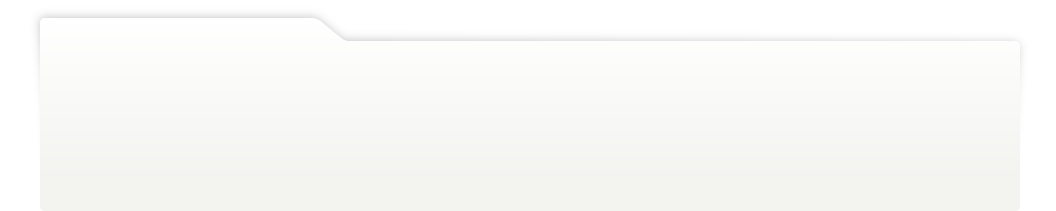
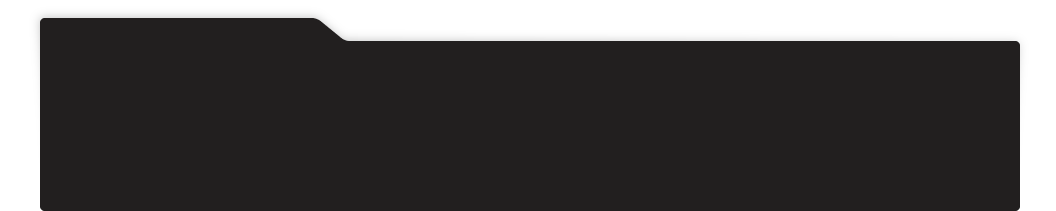
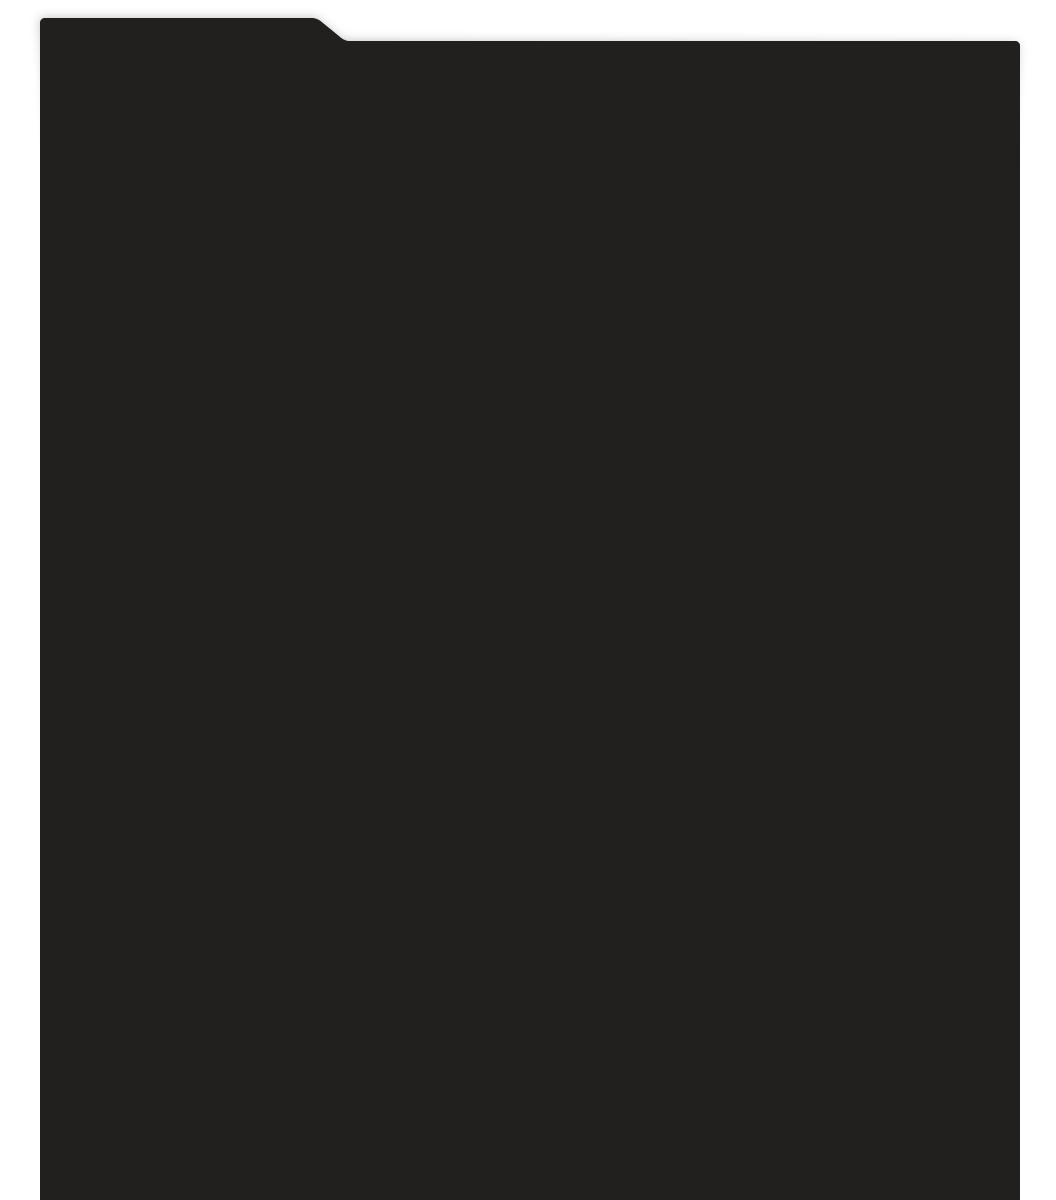
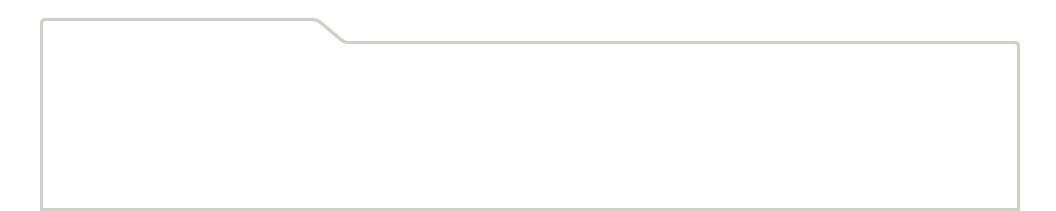
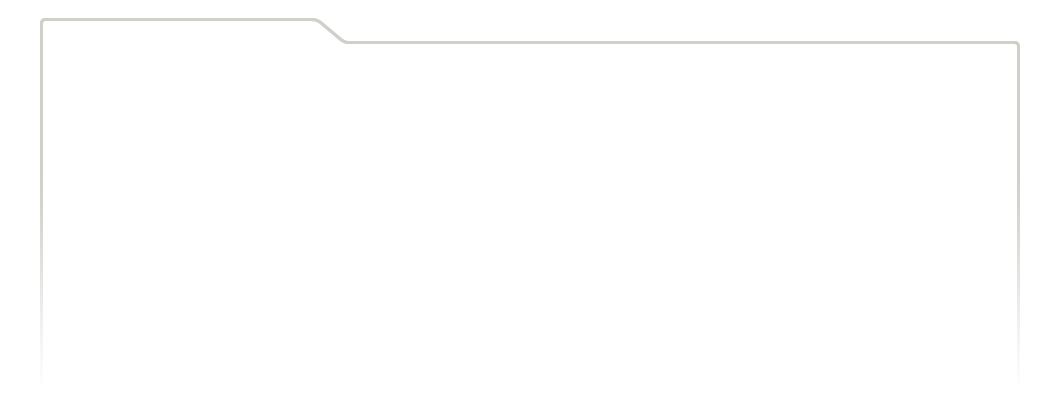
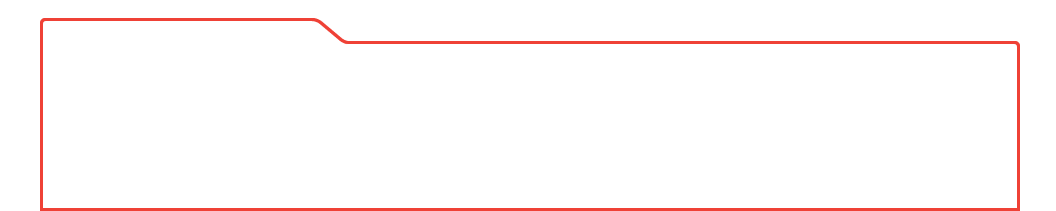
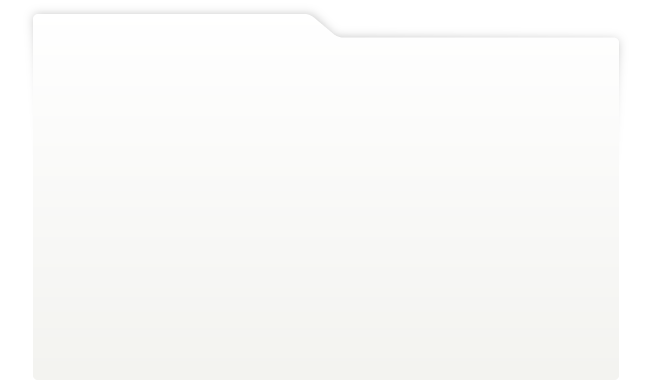
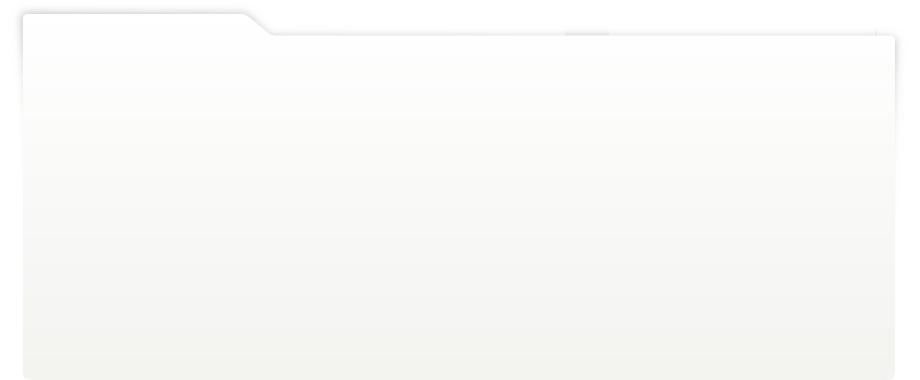
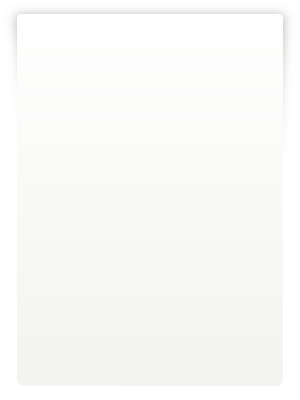
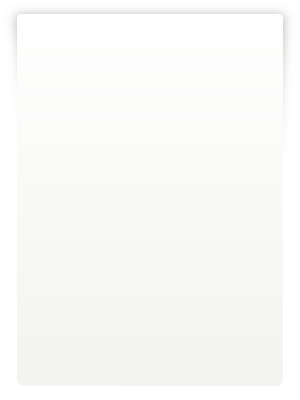
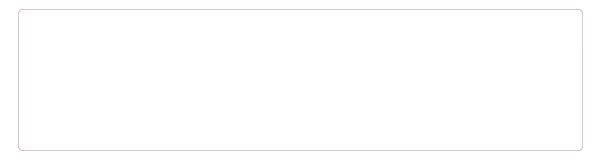
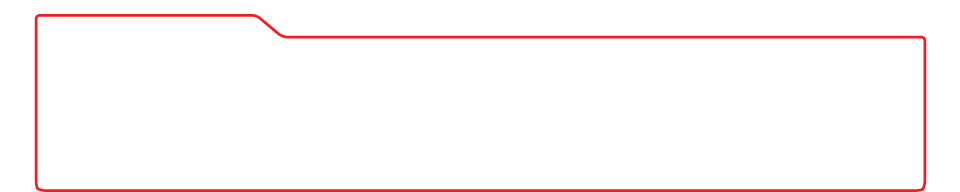
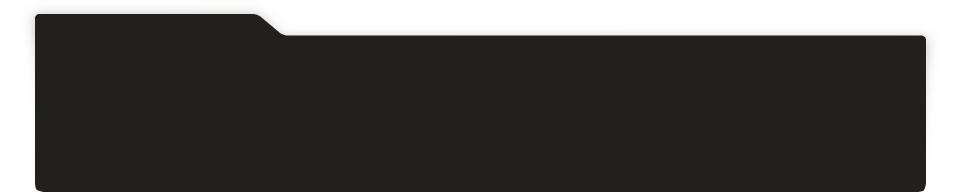
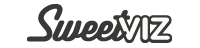
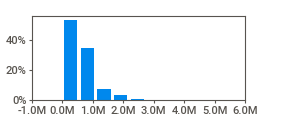
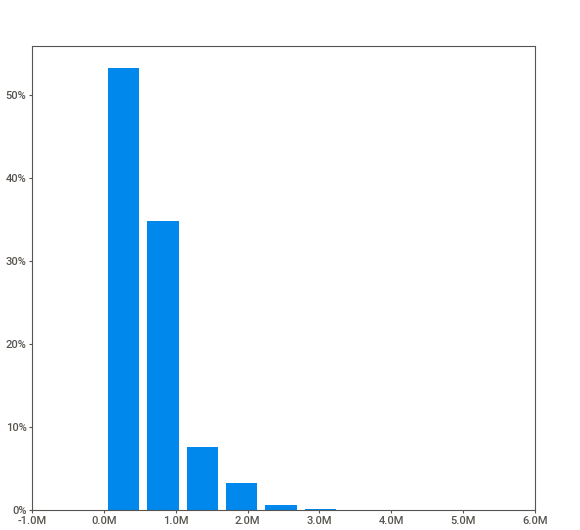
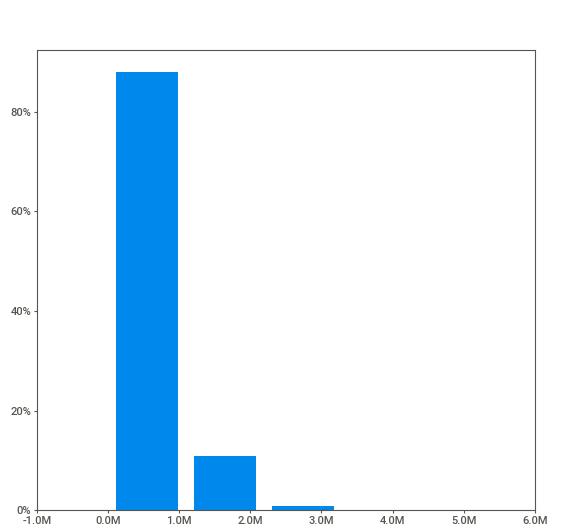
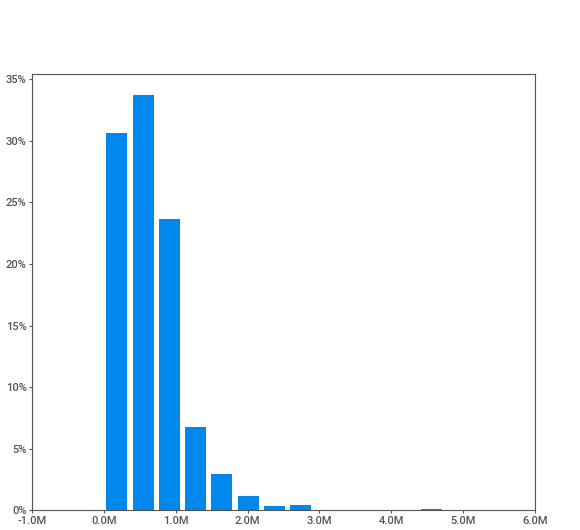
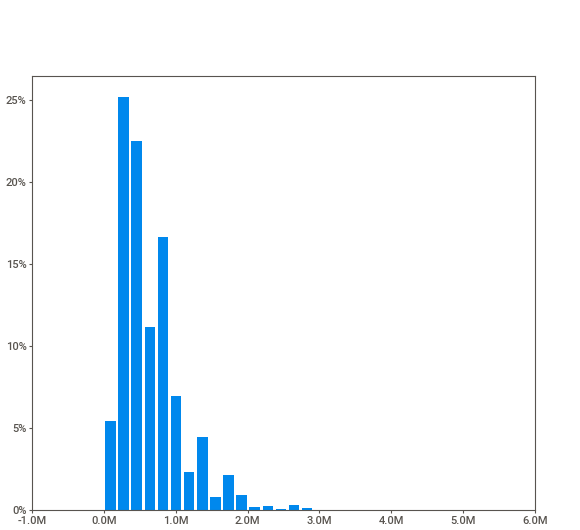
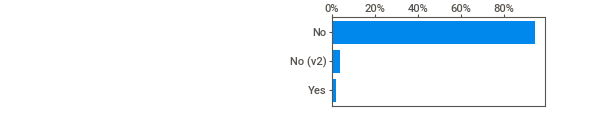
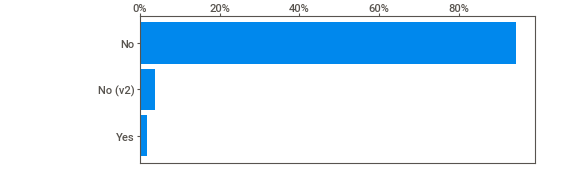
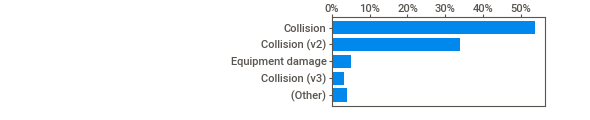
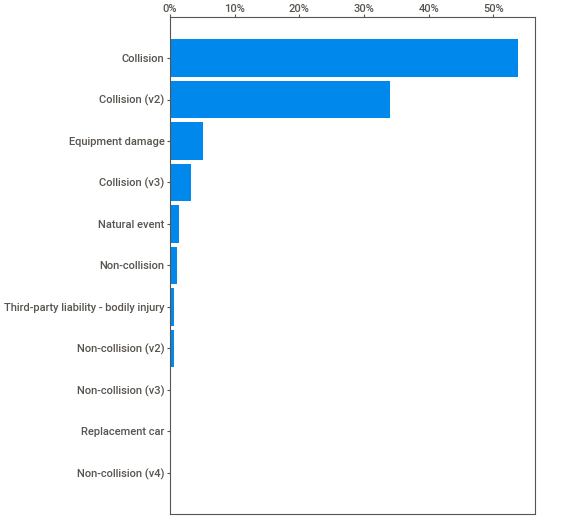
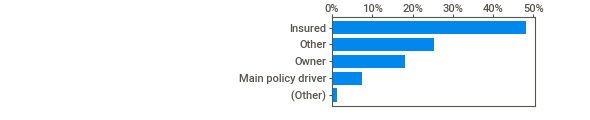
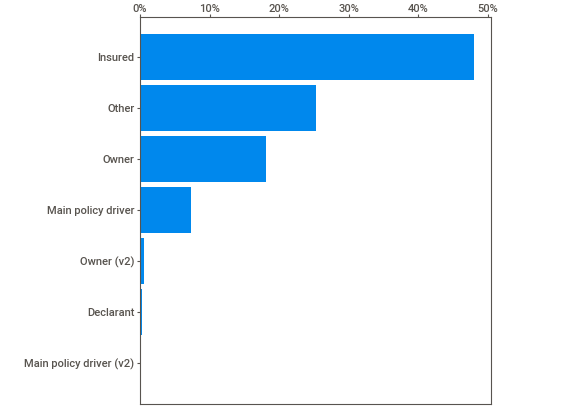
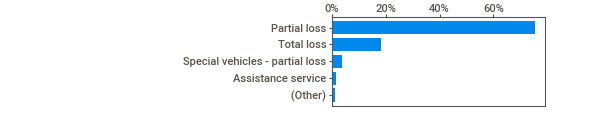
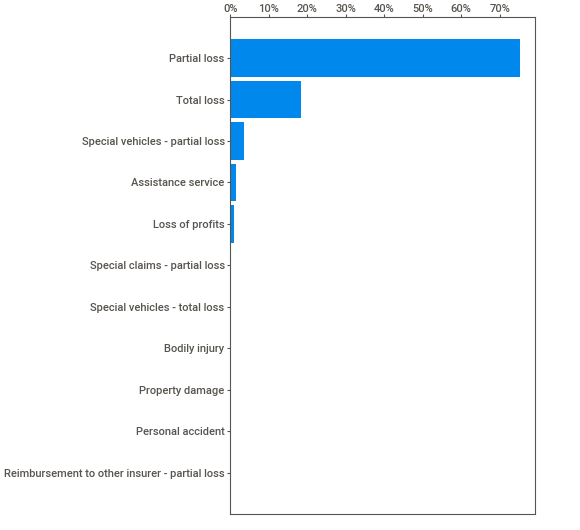
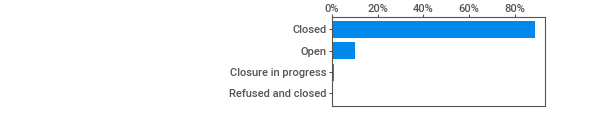
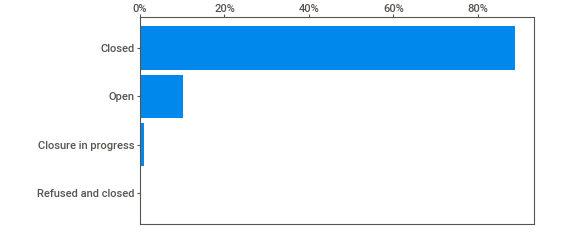
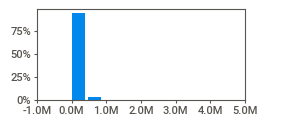
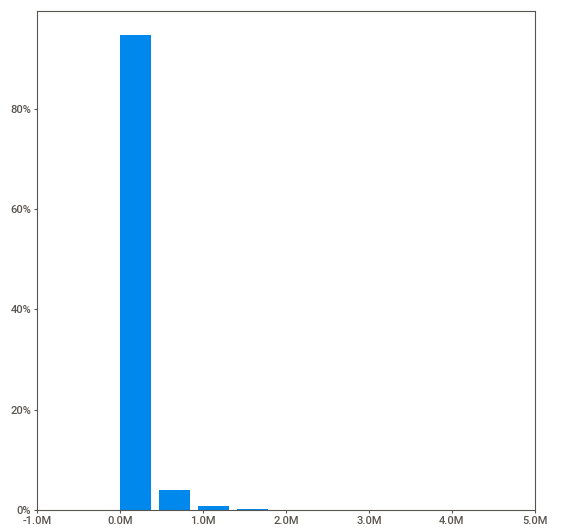
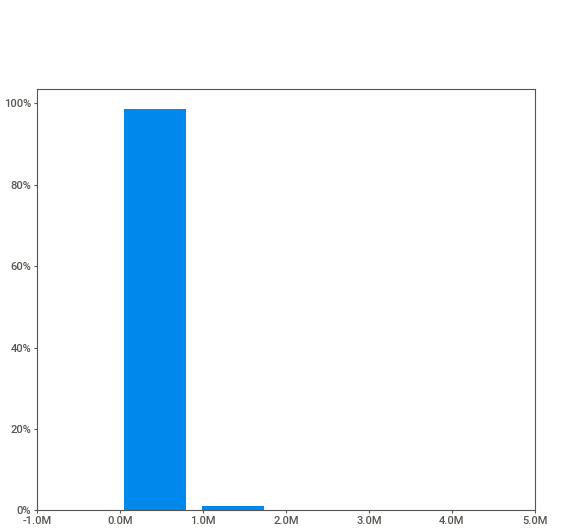
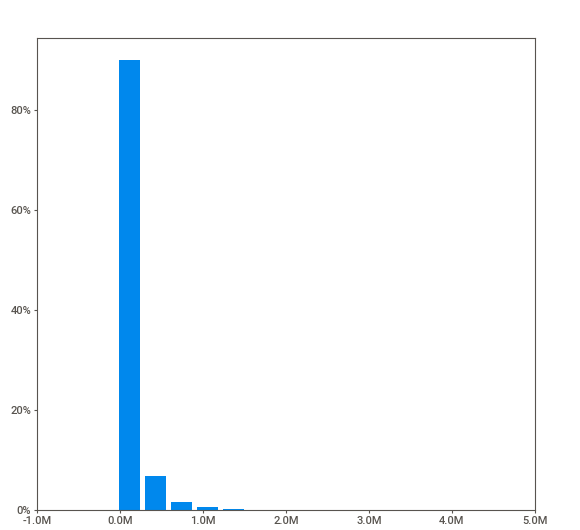
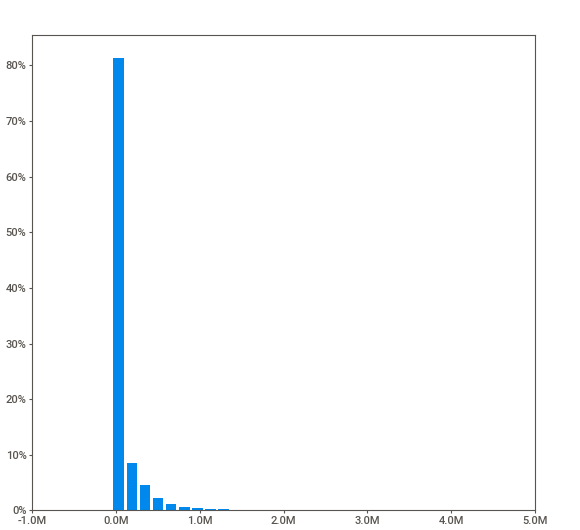
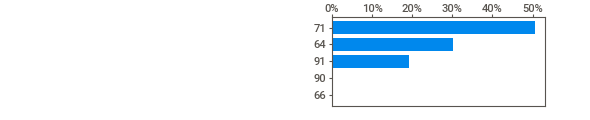
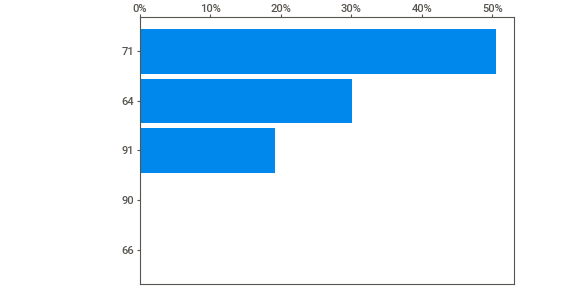
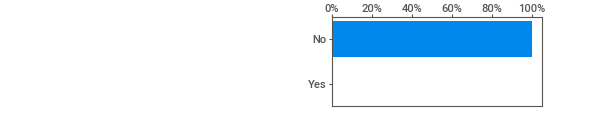
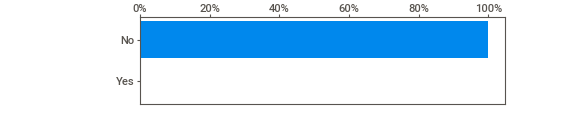
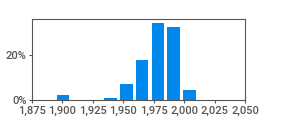
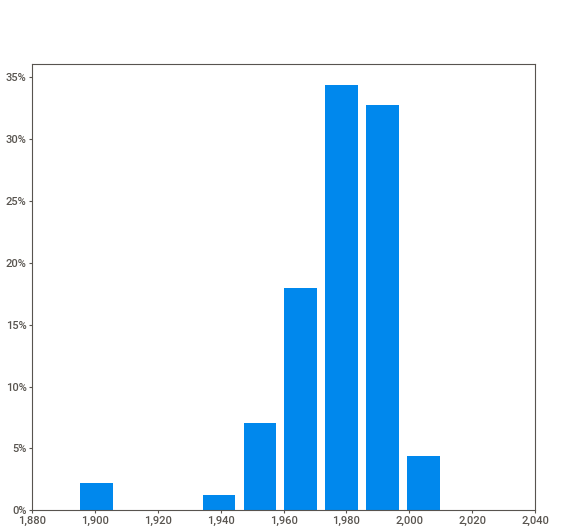
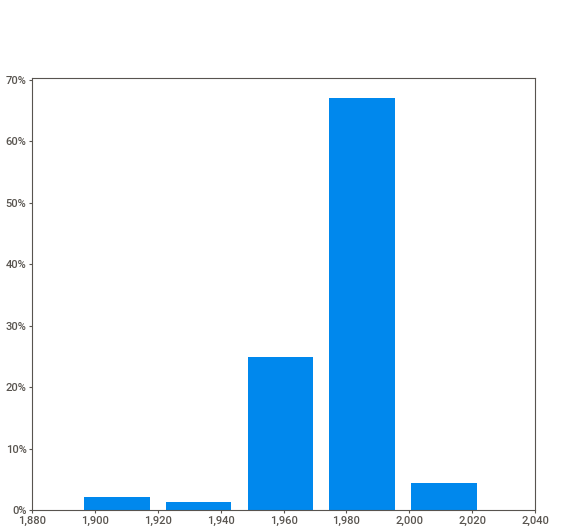
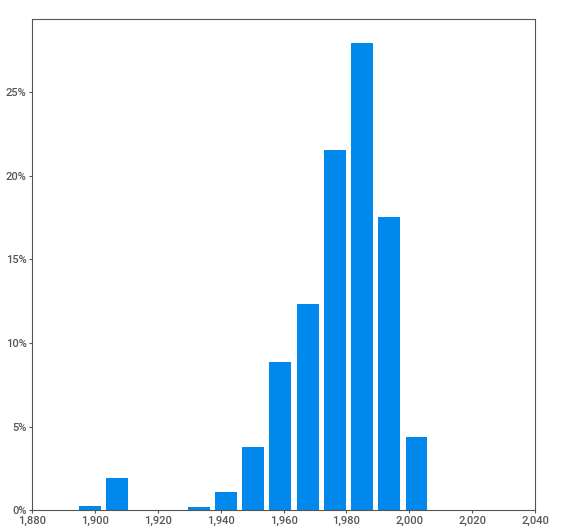
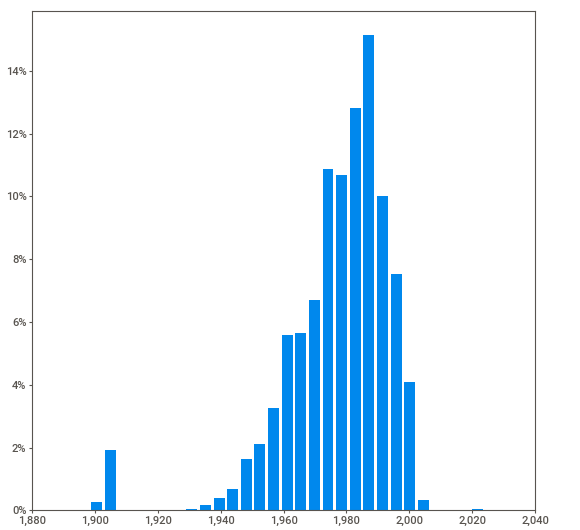
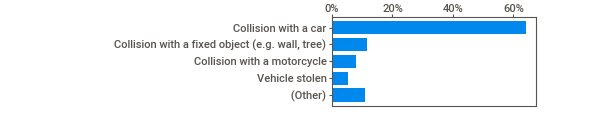
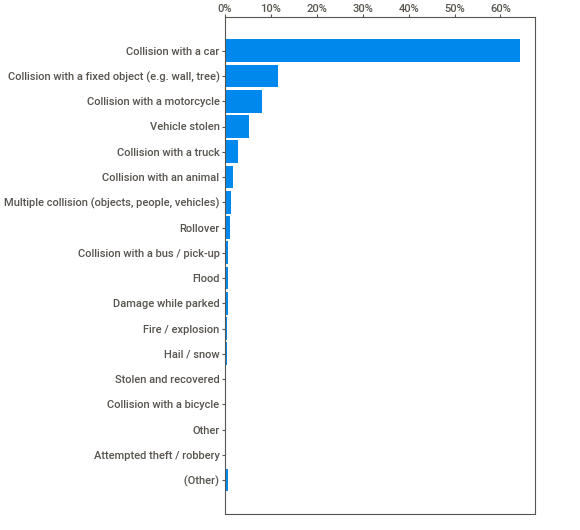
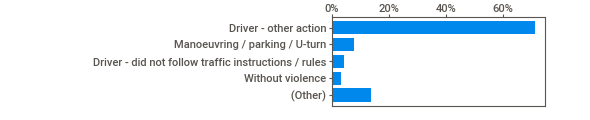
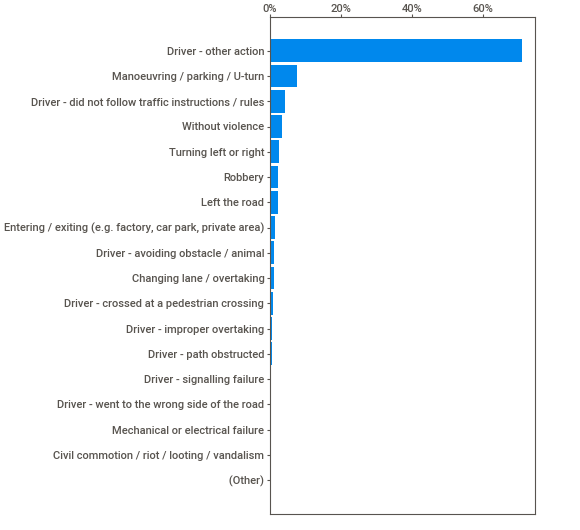
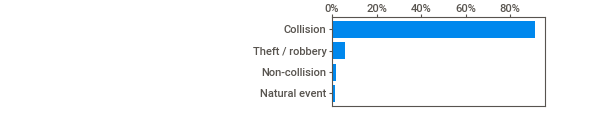
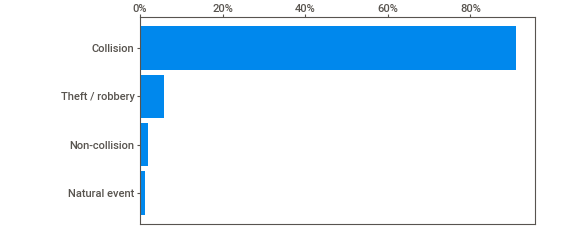
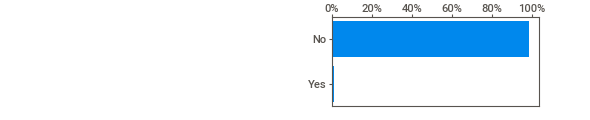
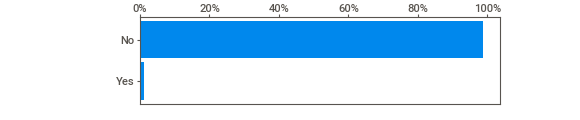
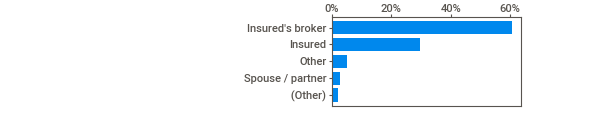
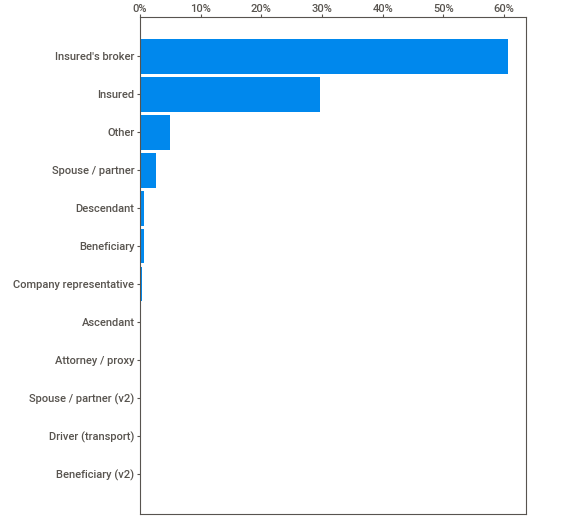
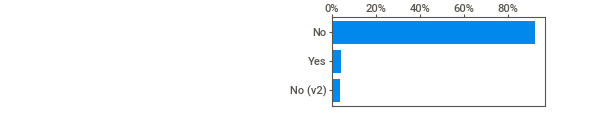
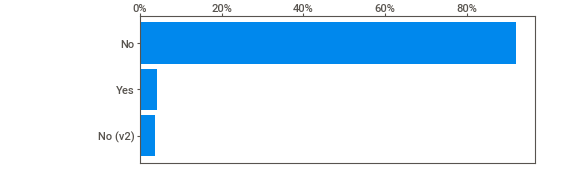
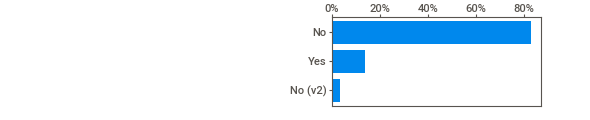
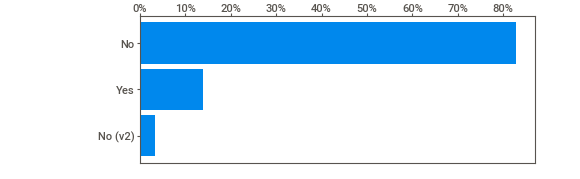
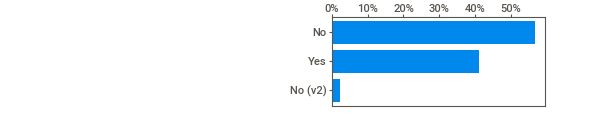
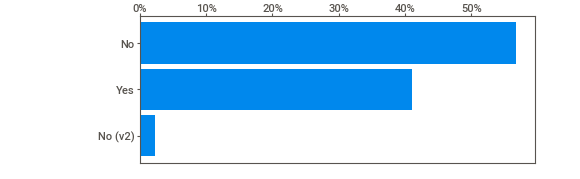
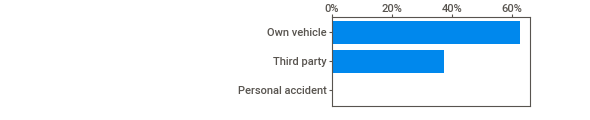
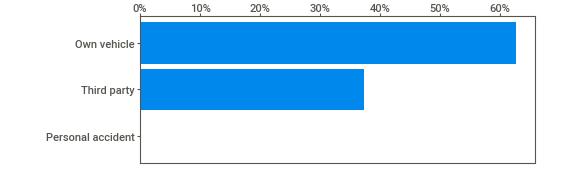
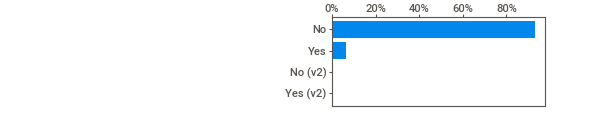
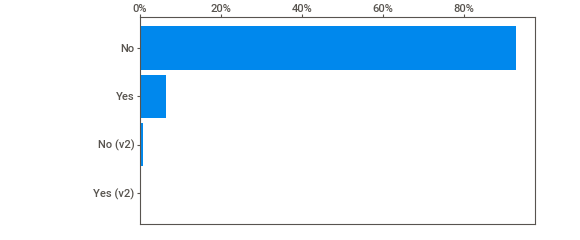
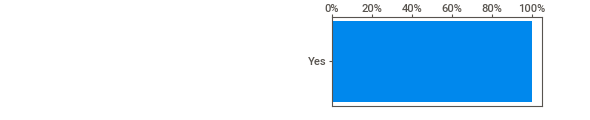
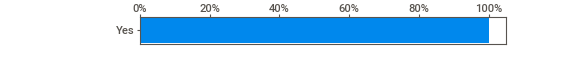
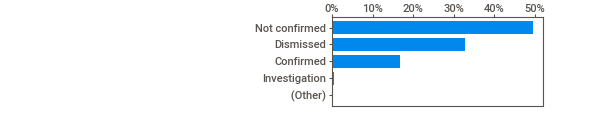
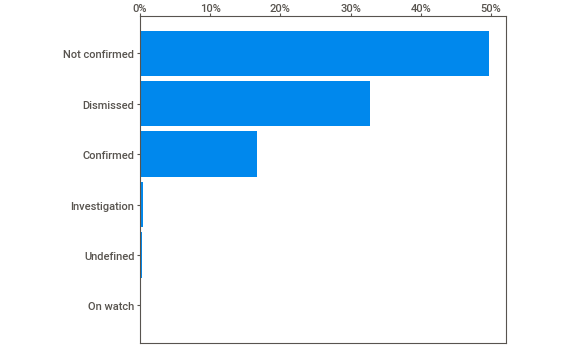
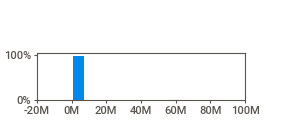
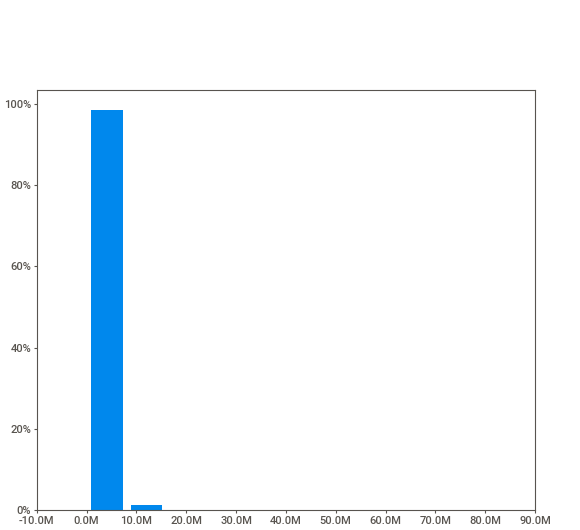
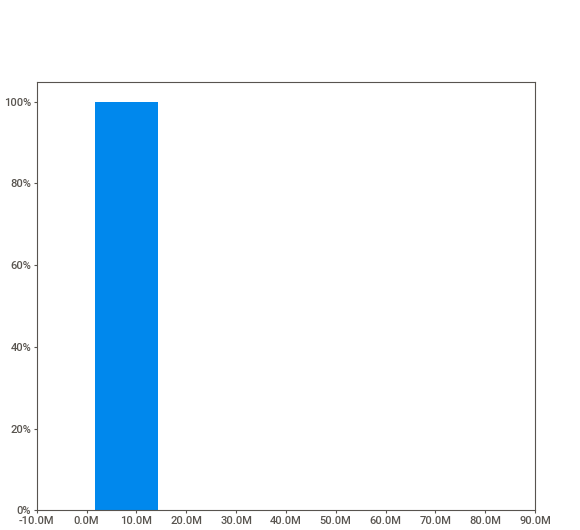
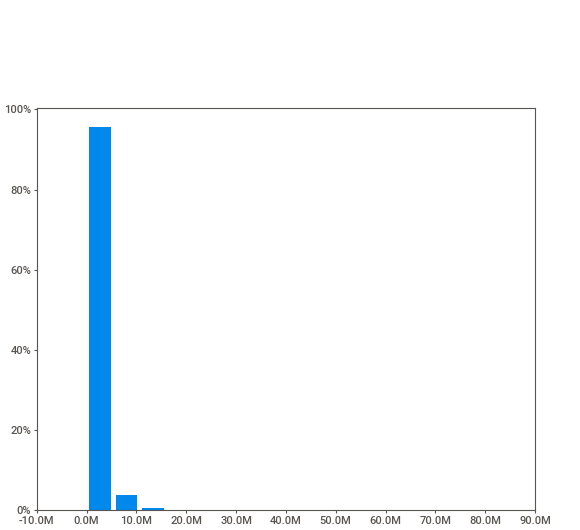
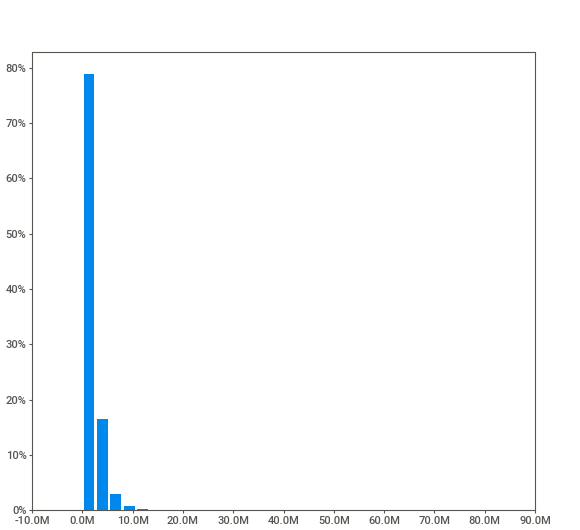
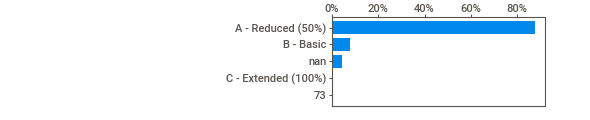
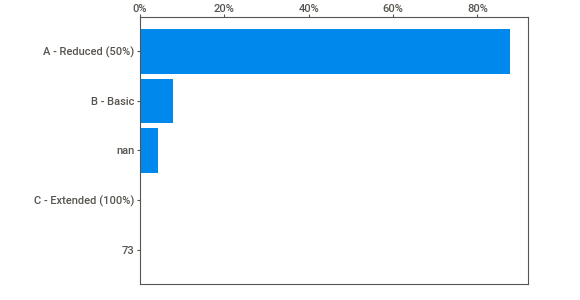
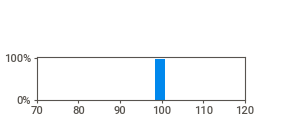
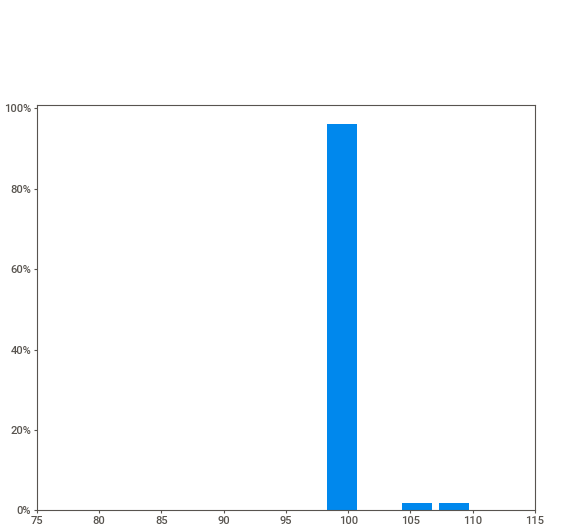
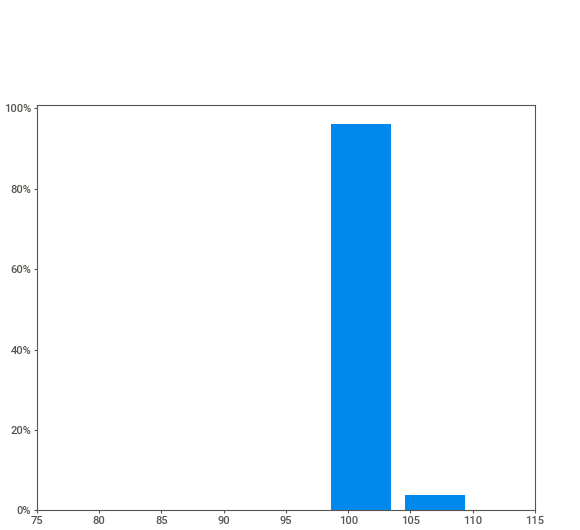
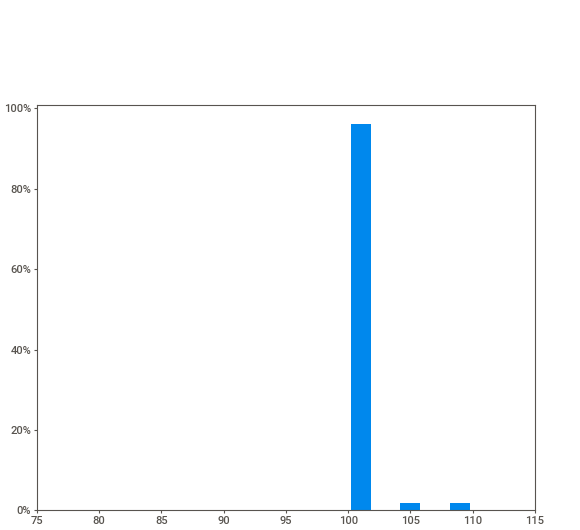
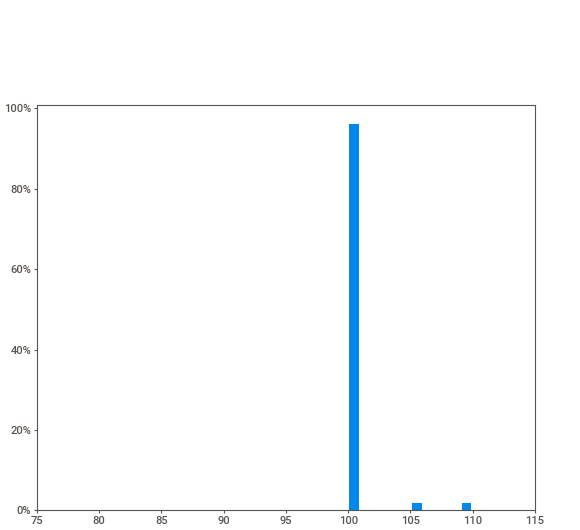
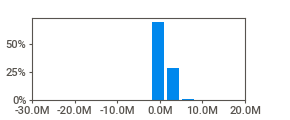
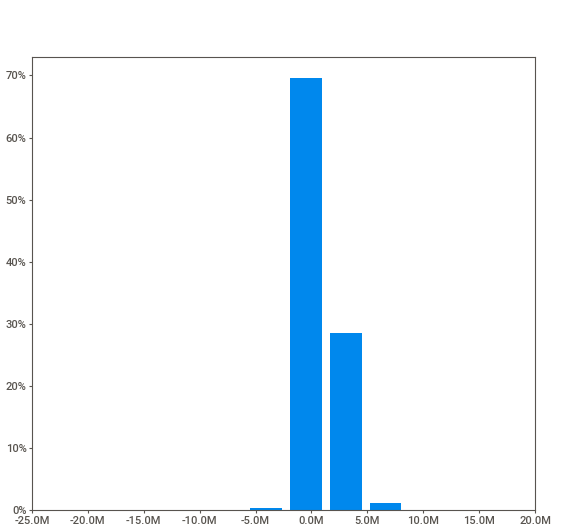
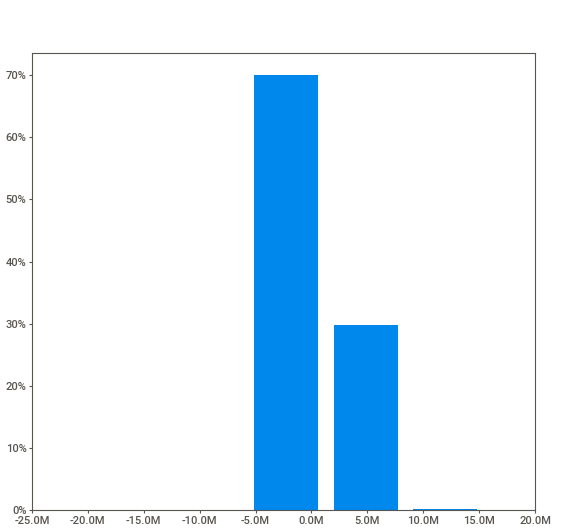
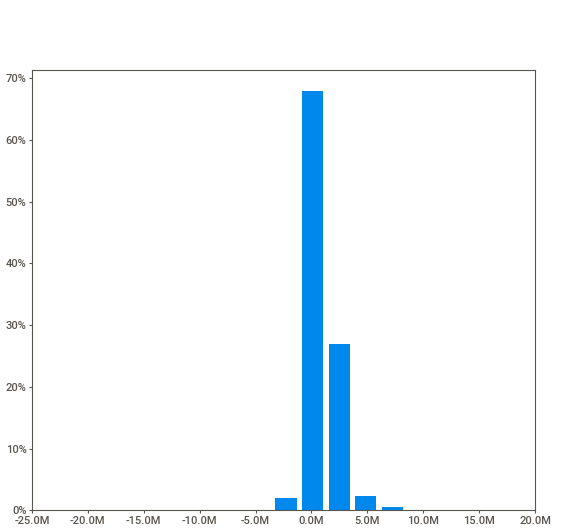
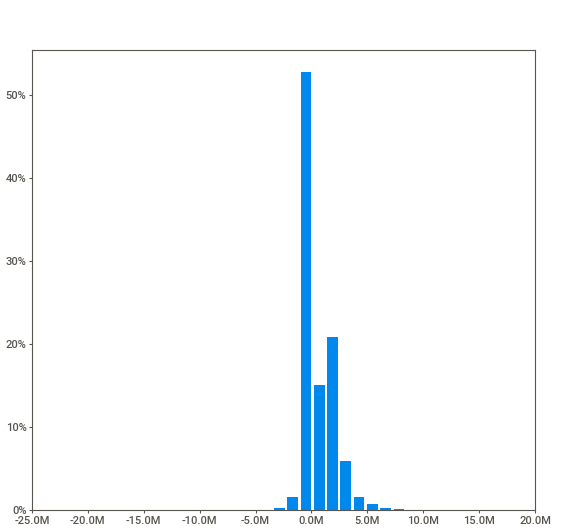
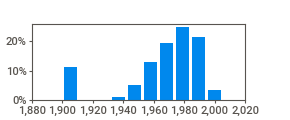
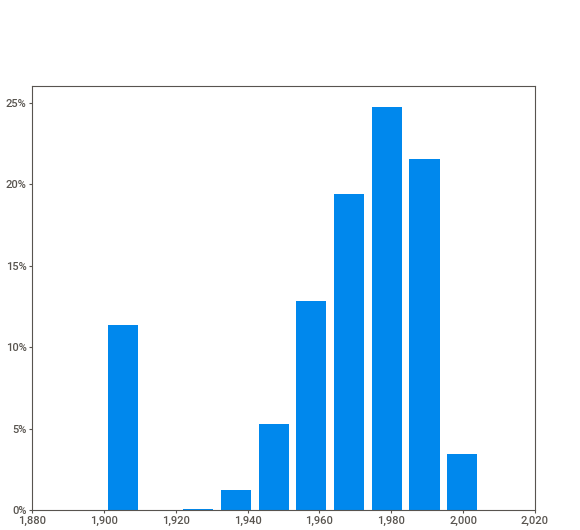
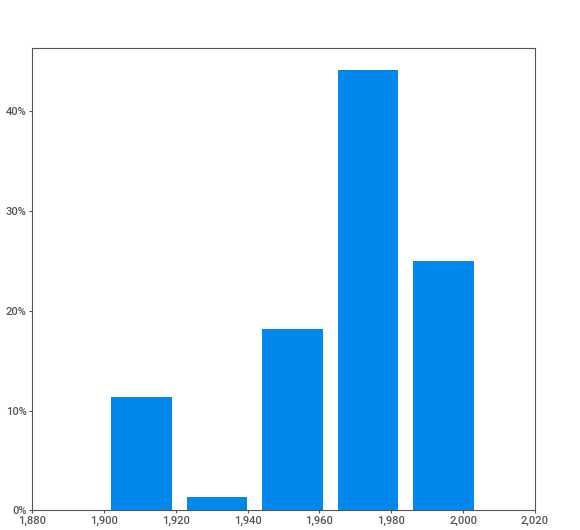
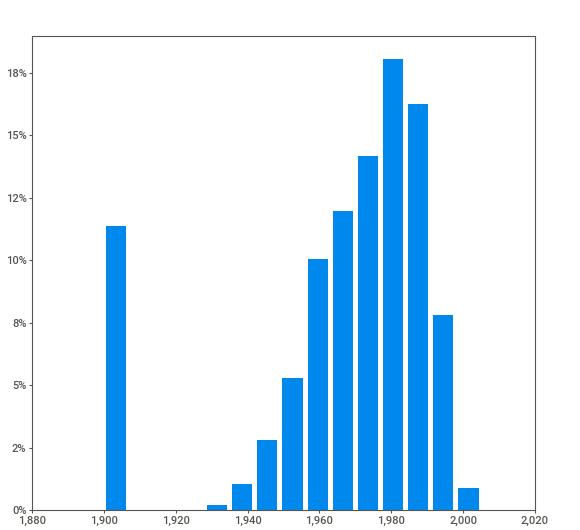
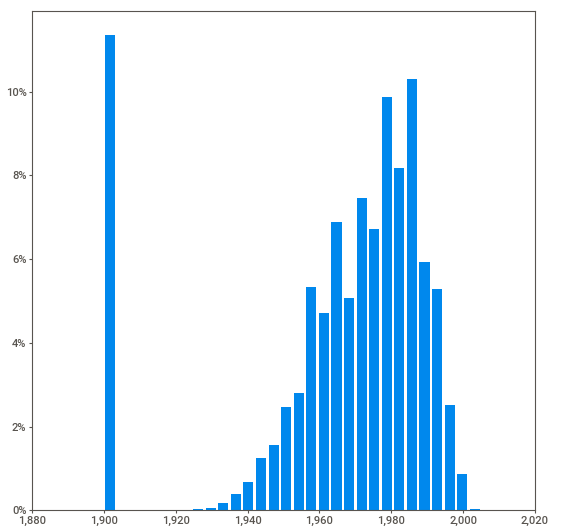
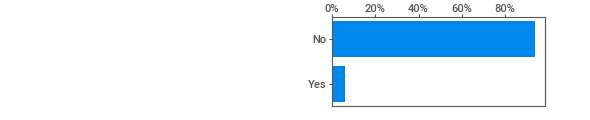
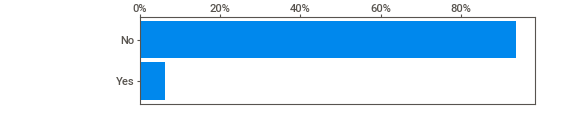
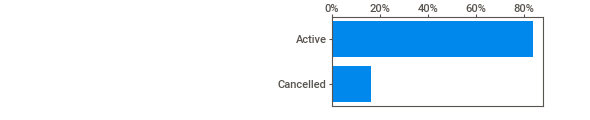
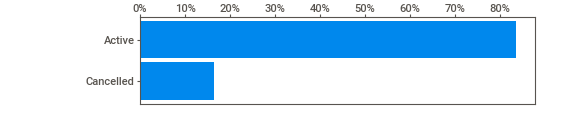
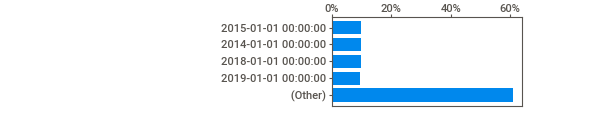
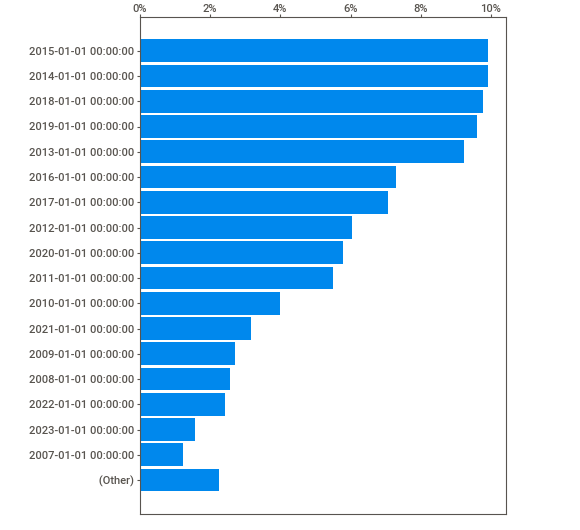
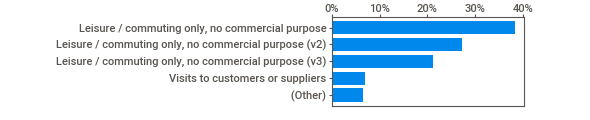
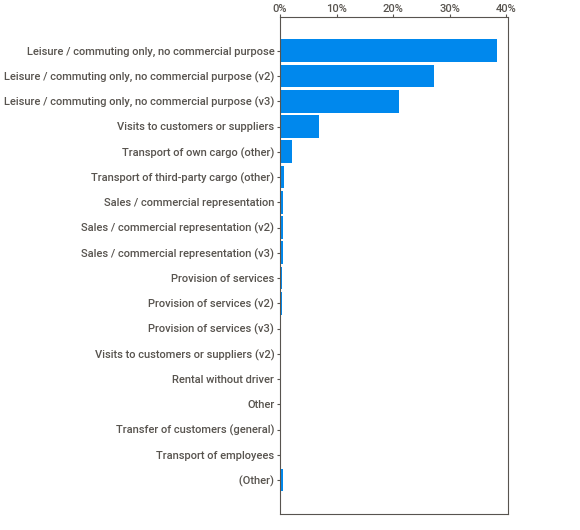
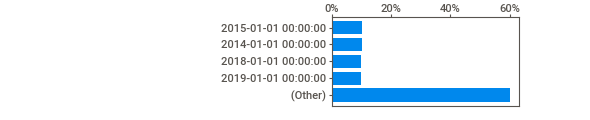
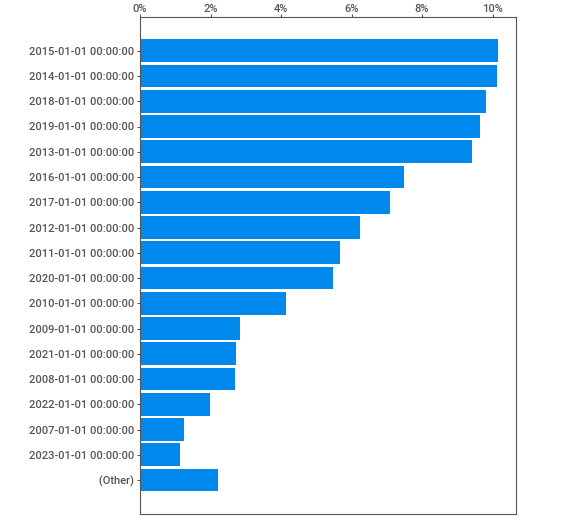
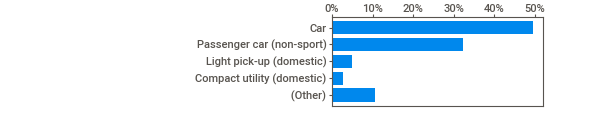
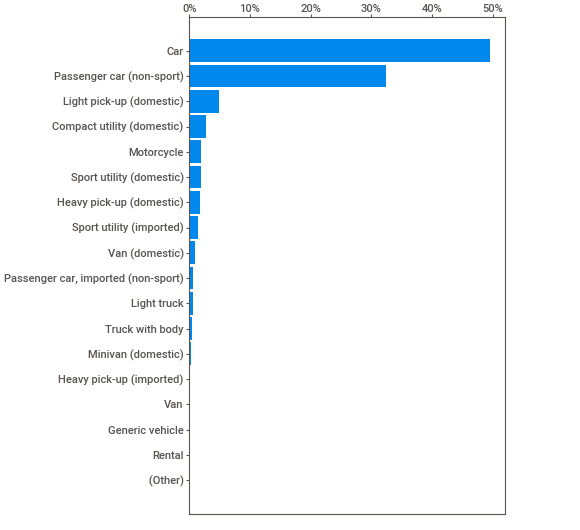
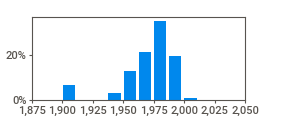
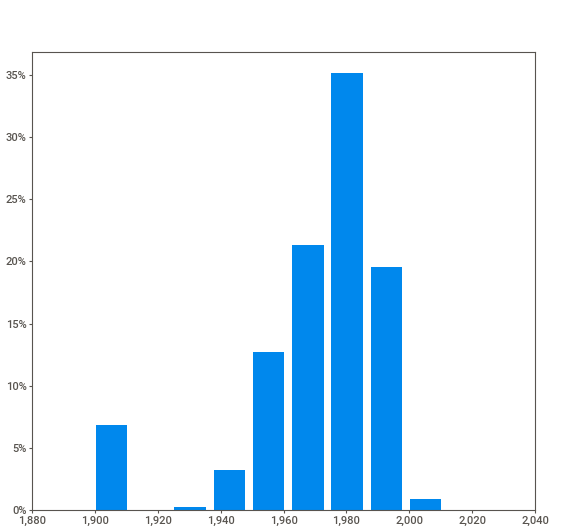
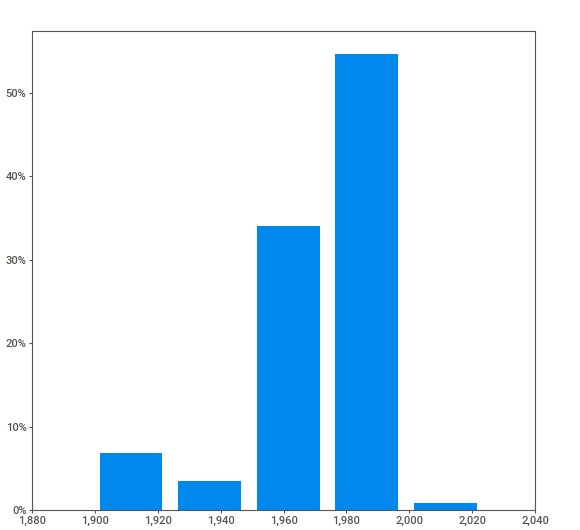
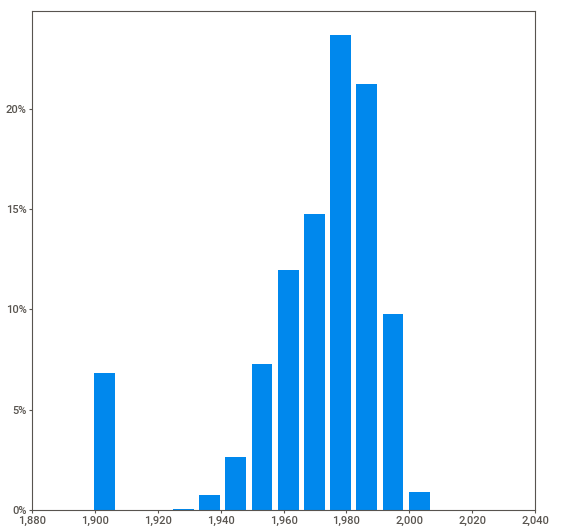
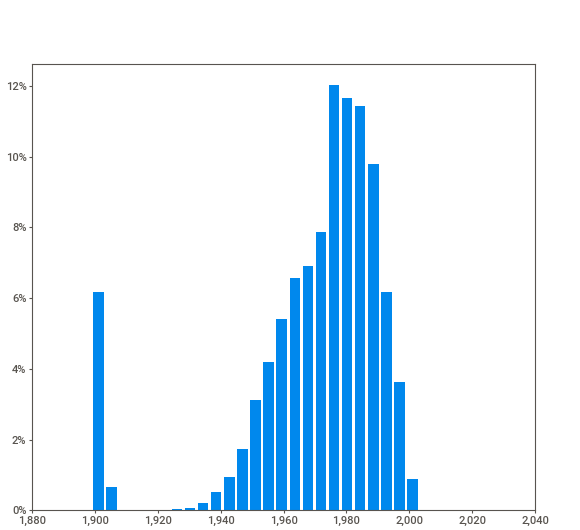
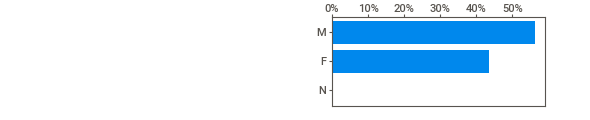
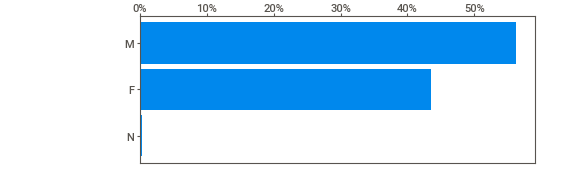
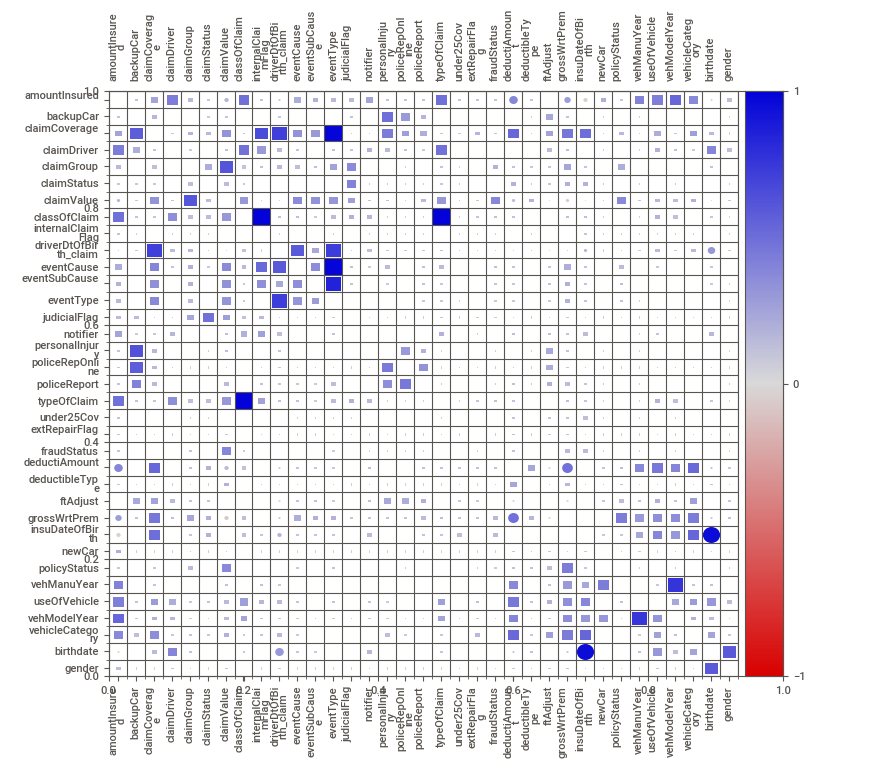
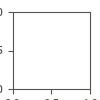

In [78]:
# Sweetviz is a handy package for automated EDA
import sweetviz as sv
import numpy as np

# Create a temp dataframe
df_temp = df.copy()

# Defining columns that hold numerical values but should be treated as strings
custom_cols = ['telephone', 'mobileNumber', 'insuredEmail', 'licensePlate', 'vinNumber_claim']
id_cols = [c for c in df_temp.columns if "Id" in c or c in custom_cols]

# Vectorized string conversion avoiding loops and protecting null values
df_temp[id_cols] = df_temp[id_cols].astype(str).where(df_temp[id_cols].notna(), np.nan)

# Run the Sweetviz analysis
sv.analyze(df_temp).show_notebook(w=1000, h=800)
del df_temp

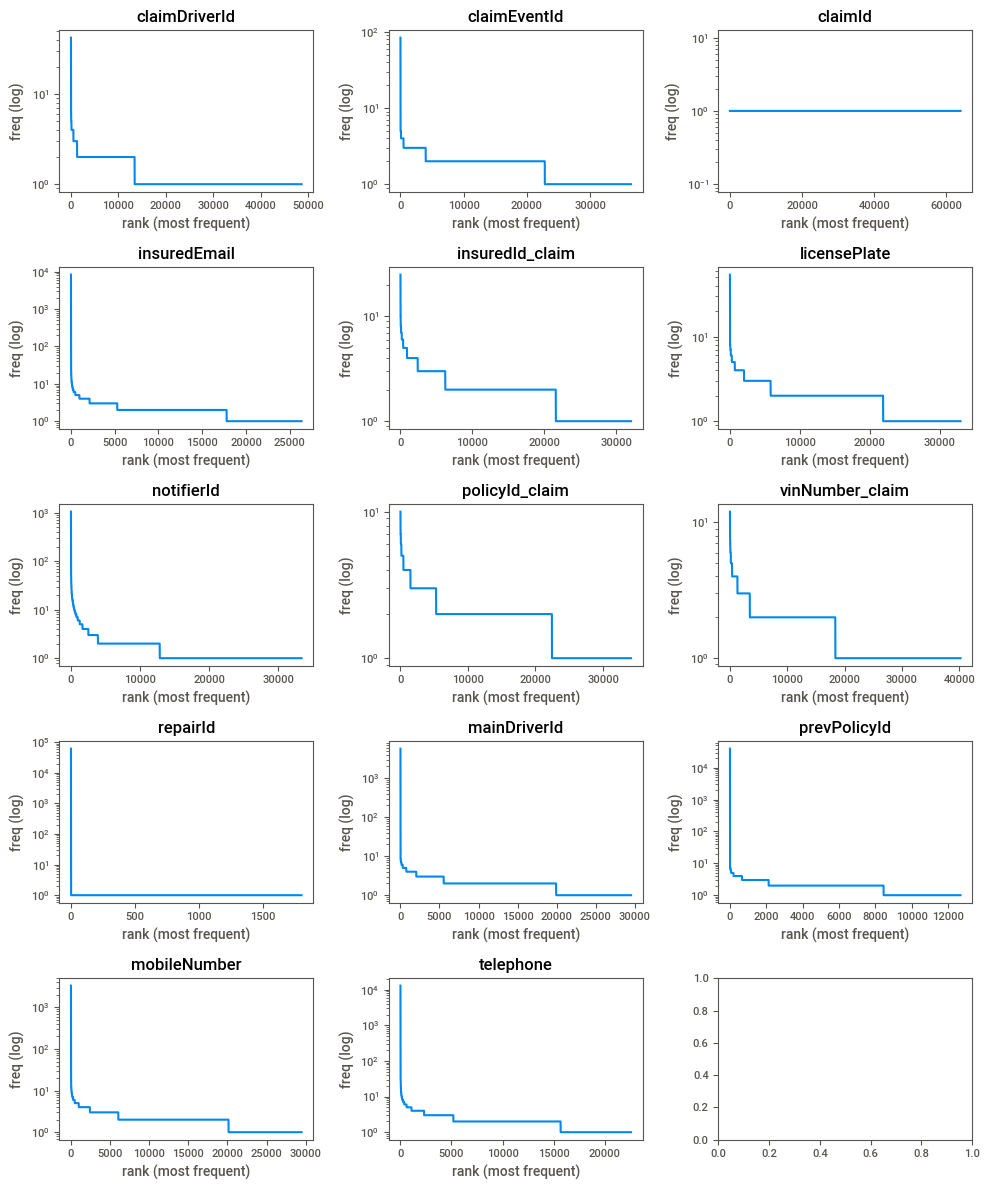

,col,top_val,n,%
0,claimDriverId,1120610.0,42.0,0.065682
1,claimEventId,NaN,84.0,0.131365
2,claimId,1278234.0,1.0,0.001564
3,insuredEmail,1286324.0,8345.0,13.050482
4,insuredId_claim,1238554.0,25.0,0.039097
5,licensePlate,1257163.0,54.0,0.084449
6,notifierId,1120610.0,1052.0,1.645190
7,policyId_claim,1277463.0,10.0,0.015639
8,vinNumber_claim,1364289.0,12.0,0.018766
9,repairId,NaN,62142.0,97.181909


In [93]:
import matplotlib.pyplot as plt
import duckdb
import pandas as pd
from utils import get_frequency_table

top_vals = []
fig, axes = plt.subplots(5, 3, figsize=(10, 12))
for ax, col in zip(axes.flat, id_cols):

    vc_full = get_frequency_table(df[col]).iloc[:-1]

    top_val = vc_full.index[0]

    top_vals += [(col, top_val, vc_full.iloc[0]["n"], vc_full.iloc[0]["%"])]

    ax.plot(range(1, len(vc_full) + 1), vc_full["n"])
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("rank (most frequent)")
    ax.set_ylabel("freq (log)")

plt.tight_layout()
plt.show()

display(
    pd.DataFrame(
        top_vals,
        columns=["col", "top_val", "n", "%"]
    )
)

## Peculiarities deep-dive

### Checking consistency for `claimEventId`

In [20]:
query = f"""
WITH groups AS (
    SELECT vinNumber_claim, dateOcurr,
           count(DISTINCT claimEventId) AS nEventIds,
           count(*)                     AS nRows
    FROM '{parquet_path}'
    GROUP BY 1, 2
    HAVING count(*) > 1
)
SELECT
    nEventIds,
    count(*)                                   AS nGroups,
    count(*) / sum(count(*)) OVER ()           AS pctGroups,
    sum(nRows)                                 AS nClaimRows
FROM groups
GROUP BY 1
ORDER BY 1
"""

display(duckdb.query(query).to_df().head(10))

,nEventIds,nGroups,pctGroups,nClaimRows
0,0,7,0.000373,15.0
1,1,18216,0.971520,38284.0
2,2,521,0.027787,1306.0
3,3,6,0.000320,21.0


- Among the **18,750 (`vinNumber_claim`, `dateOcurr`) groups** with more than one row, the vast majority (**97.2%**, 18,216 groups) map to a single `claimEventId`.
- **2.8%** of groups (521) carry two distinct `claimEventId` values on the same vehicle and day, so the ID does not reliably identify the event in those cases.
- **0.04%** of groups (7) have only null `claimEventId` values, and 0.03% (6) have three distinct IDs.
- Evidence confirms that `claimEventId` is not alone a reliable claim grouping key

### Checking for amplitude of hours between same-event claims

Since we can't fully rely on `claimEventId` as a grouping of same-event claims, a possible alternative would be to group claims that are closely related in time.  
To do that we must first find what is the typical amplitude of hours between the first and the last same-day claims

In [21]:
# The query considers only the events we are mostly sure are correct
query = f"""
WITH clean_events AS (
    SELECT
      vinNumber_claim,
      dateOcurr,
      max(claimEventId) AS claimEventId
    FROM '{parquet_path}'
    GROUP BY 1,2
    HAVING COUNT(*) > 1
       AND count(DISTINCT claimEventId) = 1
)
SELECT
    b.claimEventId,
    b.vinNumber_claim,
    b.dateOcurr,
    min(date_trunc('minute', b.hourOfEvent)) AS min_hourOfEvent,
    max(date_trunc('minute', b.hourOfEvent)) AS max_hourOfEvent,
FROM '{parquet_path}' b
JOIN clean_events a
  ON a.vinNumber_claim = b.vinNumber_claim
 AND a.dateOcurr = b.dateOcurr
 AND a.claimEventId = b.claimEventId
GROUP BY 1,2,3
HAVING
  count(DISTINCT date_trunc('minute', b.hourOfEvent)) > 1
"""

df = duckdb.query(query).to_df()

display(df.head(10))


,claimEventId,vinNumber_claim,dateOcurr,min_hourOfEvent,max_hourOfEvent
0,1153740.0,1117682,2019-03-29,1970-01-01 12:30:00,1970-01-01 13:40:00
1,1370985.0,1311790,2019-03-19,1970-01-01 08:00:00,1970-01-01 08:20:00
2,1031260.0,1089737,2019-03-26,1970-01-01 08:30:00,1970-01-01 08:40:00
3,1163173.0,1009020,2019-03-26,1970-01-01 21:00:00,1970-01-01 21:05:00
4,1278833.0,1177725,2019-03-23,1970-01-01 00:00:00,1970-01-01 23:30:00
5,1231854.0,1362691,2019-03-12,1970-01-01 15:00:00,1970-01-01 15:05:00
6,1043920.0,1213880,2019-03-25,1970-01-01 18:45:00,1970-01-01 18:46:00
7,1243036.0,1304525,2019-03-25,1970-01-01 18:30:00,1970-01-01 18:31:00
8,1223064.0,1225631,2019-03-11,1970-01-01 16:30:00,1970-01-01 16:32:00
9,1176444.0,1307253,2019-03-06,1970-01-01 16:00:00,1970-01-01 17:38:00


In [22]:
import pandas as pd
import numpy as np

# Calculate the time amplitude directly from the min and max hourOfEvent columns
min_dt = pd.to_datetime(df['min_hourOfEvent'])
max_dt = pd.to_datetime(df['max_hourOfEvent'])

amplitude_df = df[['claimEventId', 'dateOcurr']].copy()
amplitude_df['hour_amplitude'] = (max_dt - min_dt).dt.total_seconds() / 3600.0

# Present descriptive statistics
print("Descriptive Statistics of hourOfEvent Amplitude (in hours):")
display(amplitude_df['hour_amplitude'].describe())

Descriptive Statistics of hourOfEvent Amplitude (in hours):


,hour_amplitude
count,1993.000000
mean,1.265053
std,3.062491
min,0.016667
25%,0.166667
50%,0.333333
75%,0.833333
max,23.500000


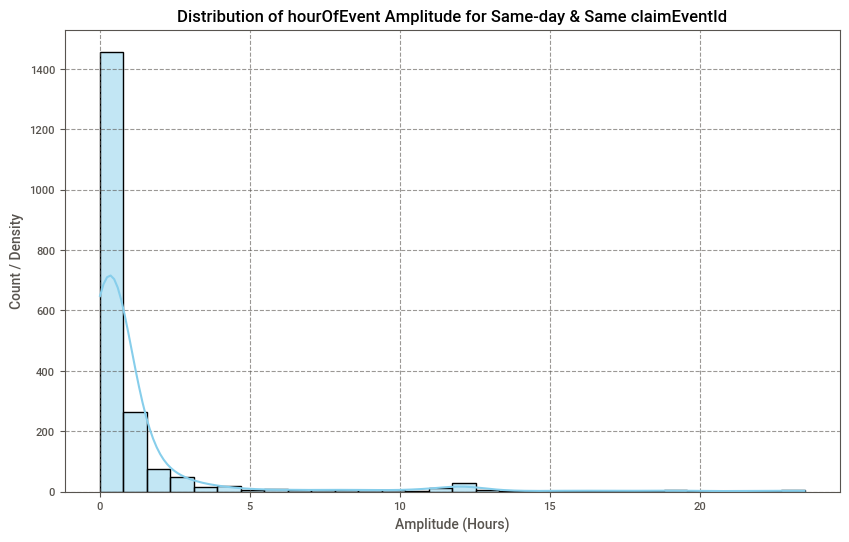

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot histogram with KDE
plt.figure(figsize=(10, 6))
sns.histplot(amplitude_df['hour_amplitude'], kde=True, bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of hourOfEvent Amplitude for Same-day & Same claimEventId')
plt.xlabel('Amplitude (Hours)')
plt.ylabel('Count / Density')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Data shows that around 75% percent of same-day event claims are made within an interval of ≈50min between the first and the last claim.
While `claimEventId` remains the main grouping key, this may be helpful to disambiguate claims with same `vinNumber_claim` and `dateOcurr`, but different `claimEventIds`.